<a href="https://colab.research.google.com/github/100522155/egci463/blob/main/digit_PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ***Import Data***

In [2]:
import pandas as pd

import io
from google.colab import files
uploaded = files.upload()
data = pd.read_csv(io.BytesIO(uploaded["digit.csv"]), header=None)


Saving digit.csv to digit.csv


# Try to predict using simple Some Classifier

In [3]:
# 1. Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [4]:
bin_digits = (data.iloc[:, :-1] > 128).astype(int)

X2 = bin_digits.values
y = data.iloc[:, -1].values
x_train, x_test, y_train, y_test = train_test_split(X2, y, test_size=0.2, random_state=42)

model_lr = LogisticRegression().fit(x_train, y_train)
print(model_lr)

LogisticRegression()


In [5]:
y_pred=model_lr.predict(x_test)

Show score of the prediction

In [6]:
np.array([y_pred ,y_test]).T

array([[7, 7],
       [1, 1],
       [7, 7],
       [3, 3],
       [3, 2],
       [7, 7],
       [7, 7],
       [2, 2],
       [1, 1],
       [9, 9],
       [0, 0],
       [3, 3],
       [8, 8],
       [1, 1],
       [1, 7],
       [7, 7],
       [9, 9],
       [0, 0],
       [6, 6],
       [8, 8],
       [7, 9],
       [9, 9],
       [5, 5],
       [7, 7],
       [1, 1],
       [9, 9],
       [9, 9],
       [4, 4],
       [2, 2],
       [5, 6],
       [9, 9],
       [6, 6],
       [8, 8],
       [3, 3],
       [5, 0],
       [6, 6],
       [1, 8],
       [1, 1],
       [4, 4],
       [1, 1],
       [9, 7],
       [1, 1],
       [9, 9],
       [2, 3],
       [0, 0],
       [1, 1],
       [0, 0],
       [0, 0],
       [8, 8],
       [0, 0],
       [1, 1],
       [3, 3],
       [2, 2],
       [8, 8],
       [3, 3],
       [2, 1],
       [1, 2],
       [0, 0],
       [5, 4],
       [1, 1],
       [9, 9],
       [5, 5],
       [6, 6],
       [9, 9],
       [1, 1],
       [0, 0],
       [9,

In [7]:
print(model_lr.score(x_train, y_train))
print(model_lr.score(x_test, y_test))

1.0
0.87


In [8]:
print('Data Size', X2.shape)

Data Size (500, 784)


### Experiment Using PCA

In [9]:
import numpy as np
X_std = X2
mean_vec = np.mean(X_std, axis=0)

In [10]:
X_std.shape

(500, 784)

Covariance matrix 
[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]
NumPy covariance matrix: 
[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


/usr/local/lib/python3.13/dist-packages/matplotlib/cbook.py:1709: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/usr/local/lib/python3.13/dist-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


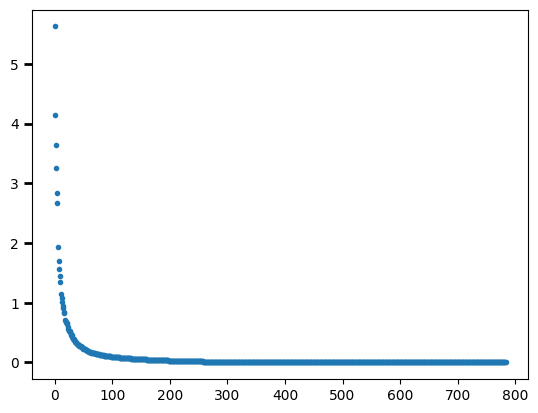

In [11]:
cov_mat = (X_std - mean_vec).T.dot((X_std - mean_vec)) / (X_std.shape[0]-1)
#Manually computes the sample covariance matrix of a standardized dataset (X_std).
print('Covariance matrix \n%s' %cov_mat) #Print covariance matrix
print('NumPy covariance matrix: \n%s' %np.cov(X_std.T)) #Computes the covariance matrix using NumPy's built-in np.cov()
# function to double-check the manual calculation.
cov_mat = np.cov(X_std.T)
from numpy import linalg as LA
values, vectors = LA.eig(cov_mat)

#values: The eigenvalues of the covariance matrix,
#which represent the amount of variance explained by each principal component.

#vectors: The eigenvectors, which represent the directions of the principal component axes

import matplotlib.pyplot as plt
plt.plot(np.sort(values)[::-1],'.')
#np.sort(values)[::-1] sorts the eigenvalues in descending order
 #(from largest to smallest) so the components capturing the most variance appear first.
plt.tick_params(axis='y',length=6, width=2)


In [12]:
np.set_printoptions(precision=2,suppress=True)
values[:50]

array([5.62+0.j, 4.15+0.j, 3.65+0.j, 3.25+0.j, 2.83+0.j, 2.68+0.j,
       1.93+0.j, 1.69+0.j, 1.56+0.j, 1.45+0.j, 1.34+0.j, 1.14+0.j,
       1.07+0.j, 1.01+0.j, 0.94+0.j, 0.91+0.j, 0.84+0.j, 0.82+0.j,
       0.71+0.j, 0.67+0.j, 0.67+0.j, 0.66+0.j, 0.65+0.j, 0.6 +0.j,
       0.57+0.j, 0.53+0.j, 0.53+0.j, 0.52+0.j, 0.47+0.j, 0.47+0.j,
       0.45+0.j, 0.43+0.j, 0.4 +0.j, 0.39+0.j, 0.38+0.j, 0.36+0.j,
       0.35+0.j, 0.35+0.j, 0.33+0.j, 0.31+0.j, 0.31+0.j, 0.3 +0.j,
       0.29+0.j, 0.28+0.j, 0.28+0.j, 0.27+0.j, 0.26+0.j, 0.26+0.j,
       0.25+0.j, 0.24+0.j])

You can find Covariance matrix manually or use Library

# USING PCA LIBRARY

In [13]:
from sklearn.decomposition import PCA

# Initialize PCA to retain enough principal components to explain
# 98% of the total variance (eigenvalue sum) in the dataset
pca = PCA(0.98)  # Keep 98% Eigen Value --> Try to modify this

# Fit the PCA model to the standardized data (X_std) and project it
# onto the new lower-dimensional principal component space
X_new = pca.fit_transform(X_std)

# Extract the explained variance (which correspond to the eigenvalues)
# for the selected components
eig_vals = pca.explained_variance_

# Print the PCA model configuration/object details
print('Eigenvectors \n%s' % pca)

# Print the array of eigenvalues (explained variance per retained component)
print('\nEigenvalues \n%s' % eig_vals)

# Print the total number of components selected to meet the 98% variance threshold
print('\n Number of values \n%s' % len(eig_vals))

Eigenvectors 
PCA(n_components=0.98)

Eigenvalues 
[5.62 4.15 3.65 3.25 2.83 2.68 1.93 1.69 1.56 1.45 1.34 1.14 1.07 1.01
 0.94 0.91 0.84 0.82 0.71 0.67 0.67 0.66 0.65 0.6  0.57 0.53 0.53 0.52
 0.47 0.47 0.45 0.43 0.4  0.39 0.38 0.36 0.35 0.35 0.33 0.31 0.31 0.3
 0.29 0.28 0.28 0.27 0.26 0.26 0.25 0.24 0.23 0.23 0.22 0.22 0.21 0.21
 0.2  0.2  0.19 0.18 0.18 0.18 0.17 0.17 0.17 0.17 0.16 0.16 0.16 0.15
 0.15 0.15 0.15 0.14 0.14 0.14 0.14 0.13 0.13 0.13 0.13 0.12 0.12 0.12
 0.12 0.12 0.12 0.12 0.11 0.11 0.11 0.11 0.11 0.11 0.1  0.1  0.1  0.1
 0.1  0.1  0.1  0.1  0.09 0.09 0.09 0.09 0.09 0.09 0.09 0.09 0.09 0.09
 0.08 0.08 0.08 0.08 0.08 0.08 0.08 0.08 0.08 0.08 0.07 0.07 0.07 0.07
 0.07 0.07 0.07 0.07 0.07 0.07 0.07 0.07 0.07 0.07 0.06 0.06 0.06 0.06
 0.06 0.06 0.06 0.06 0.06 0.06 0.06 0.06 0.06 0.06 0.05 0.05 0.05 0.05
 0.05 0.05 0.05 0.05 0.05 0.05 0.05 0.05 0.05 0.05 0.05 0.05 0.05 0.05
 0.05 0.05 0.04 0.04 0.04 0.04 0.04 0.04 0.04 0.04 0.04 0.04 0.04 0.04
 0.04 0.04 0.04 0.04 0.04 0.

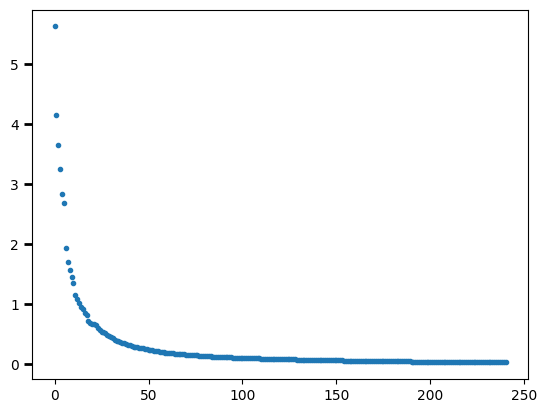

In [14]:
import matplotlib.pyplot as plt

# Create a scree plot of the eigenvalues (`eig_vals`)
# resulting from the Scikit-Learn PCA transformation
plt.plot(eig_vals, '.')

# Customize the appearance of the y-axis ticks:
# - `length=6`: Sets the length of the tick marks to 6 points
# - `width=2`: Sets the width/thickness of the tick marks to 2 points
plt.tick_params(axis='y', length=6, width=2)

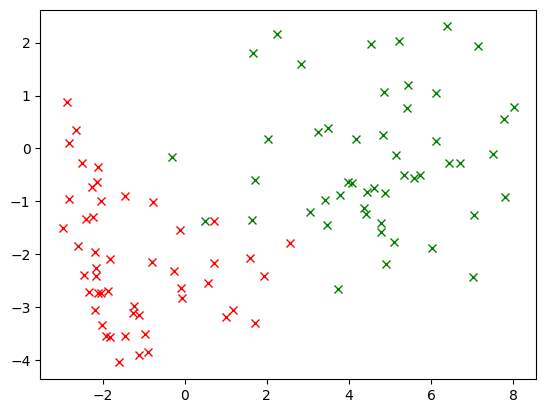

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# Extract the principal axes (eigenvectors) from the trained PCA model
eig_vecs = pca.components_

# Manually project the centered dataset onto the principal components
# (This achieves the exact same result as `pca.transform(X_std)`)
Projdata = np.dot((X_std - mean_vec), eig_vecs.T)
# Alternative way using built-in scikit-learn method:
# Projdata = pca.transform(X_std)

# Clear the current matplotlib figure to start with a blank plot
plt.clf()

# Create an array of indices from 0 to 49 to select the first group of data points
# (e.g., samples representing a specific digit class)
digit = np.arange(50)  # Choose index of the digit ==> 0

# Plot the projection on the 1st (x-axis) and 2nd (y-axis) principal components
# for the first group of data points using green 'x' markers
plt.plot(Projdata[digit, 0], Projdata[digit, 1], 'x', color='g')

# Shift the indices forward by 200 to select a different group of data points
digit = digit + 200  # Choose another set of index ==> 4

# Plot the projection for the second group of data points using red 'x' markers
plt.plot(Projdata[digit, 0], Projdata[digit, 1], 'x', color='r')

# Render and display the final scatter plot
plt.show()

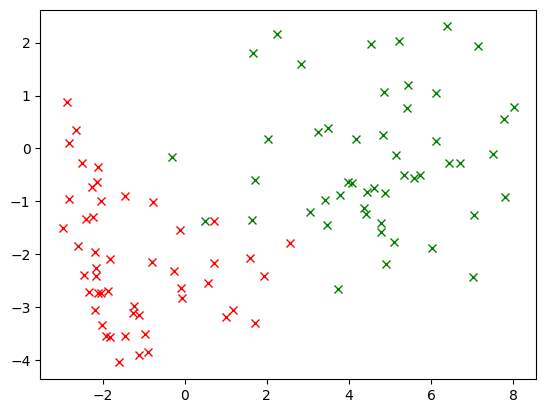

In [16]:
X_proj=pca.transform(X_std)

digit=np.arange(50)#Choose index of the digit

plt.plot(X_proj[digit,0],X_proj[digit,1],'x',color='g')
digit=digit+200 # Choose another set of index
plt.plot(X_proj[digit,0],X_proj[digit,1],'x',color='r')


In [17]:
import matplotlib.pyplot as plt

Projdata=np.dot((X_std-mean_vec),eig_vecs.T) # Make a projection on eigvector
#This line manually projects your standardized data onto the principal
#component axes (eigenvectors), which is the core step of performing
#PCA dimensionality reduction.

#It achieves the exact same mathematical result as calling pca.transform(X_std).


In [18]:
recon=np.dot( Projdata,eig_vecs) #Reversed based on the projection
#recon=pca.inverse_transform(Projdata)
recon.shape

(500, 784)

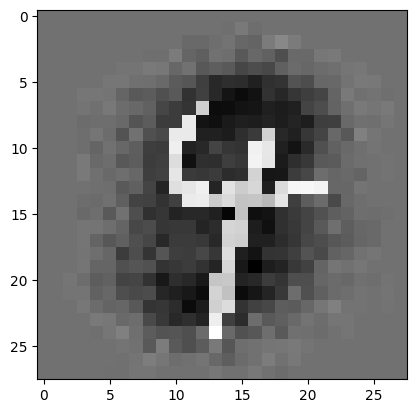

In [19]:
plt.imshow(np.reshape(recon[245],[28,28]),cmap='gray') #index [1] is a selected image of your choice
plt.show()

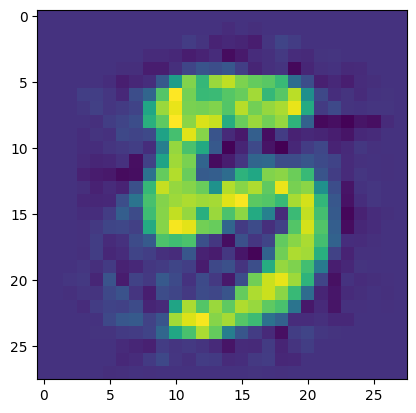

In [20]:
Projdata100=np.dot((X_std-mean_vec),eig_vecs[:100,:].T) # Make a projection on eigvector

recon100=np.dot( Projdata100,eig_vecs[:100,:])+mean_vec
plt.imshow(np.reshape(recon100[266,:],[28,28])) #index [266] --> Digit 5 is a selected image of your choice


In [21]:
eig_vecs.sort

<function ndarray.sort>

In [22]:
print(eig_vecs)

[[-0. -0.  0. ... -0. -0. -0.]
 [-0.  0.  0. ... -0. -0. -0.]
 [ 0.  0.  0. ...  0.  0.  0.]
 ...
 [ 0. -0. -0. ...  0.  0.  0.]
 [-0.  0.  0. ...  0.  0.  0.]
 [-0.  0. -0. ... -0. -0. -0.]]


In [23]:


# This is an extremely inefficient function.
def pca_com(com, images):
    # percentage should be a decimal from 0 to 1
    pca = PCA(n_components=com)
    pca.fit(images)
    components = pca.transform(images)
    approxOriginal = pca.inverse_transform(components)
    return approxOriginal

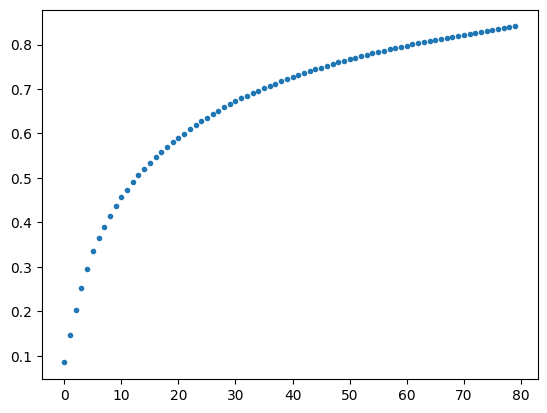

In [24]:
pca = PCA(n_components=80)
#Sets up the PCA model to calculate and keep exactly 80 principal components
pca.fit(X_std)
#Computes the principal components (eigenvectors and eigenvalues) based on your
#standardized dataset (X_std), learning the directions of maximum variance.
# Fit the PCA model to your standardized data (X_std)
# to learn the principal axes (eigenvectors) and their variance


# 1. `pca.explained_variance_ratio_`: Gets the fraction of total variance explained by each individual component.
# 2. `np.cumsum(...)`: Computes the cumulative sum of these variances (e.g., component 1 + 2 + 3...).
# 3. `plt.plot(..., '.')`: Plots this cumulative variance curve as a series of dots.
plt.plot(np.cumsum(pca.explained_variance_ratio_), '.')

# Render and display the cumulative explained variance plot
plt.show()

<Figure size 640x480 with 0 Axes>

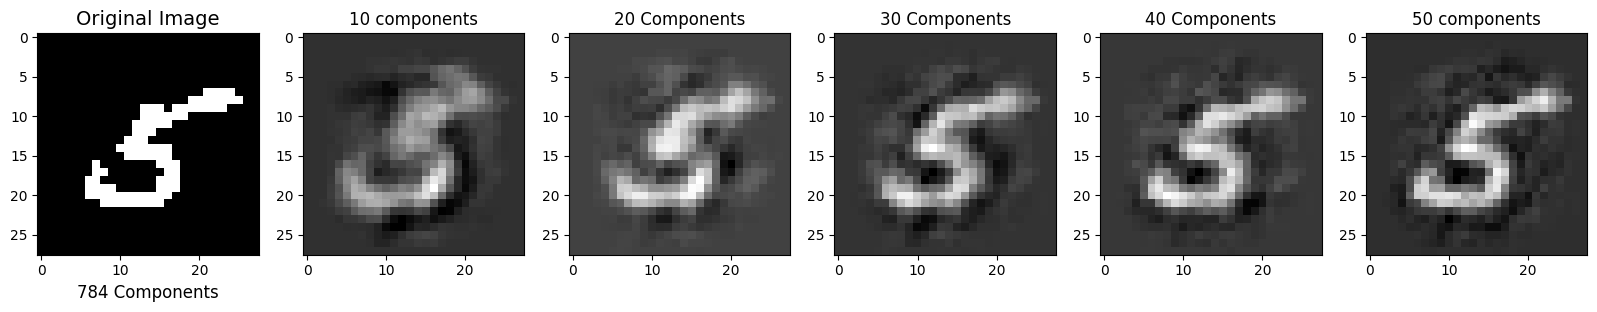

In [25]:
plt.clf()
plt.figure(figsize=(20,4));

# Original Image (784 components)
plt.subplot(1, 6, 1);
plt.imshow(X_std[260,:].reshape(28,28),
              cmap = plt.cm.gray, interpolation='nearest');
plt.xlabel('784 Components', fontsize = 12)
plt.title('Original Image', fontsize = 14);


#plots a reconstructed image of a single data point (the 260th sample)
# after it has been compressed and reconstructed using 10 principal components.
# 10 principal components
plt.subplot(1, 6, 2);
#Splits the plotting window into a grid of 1 row and 6 columns,
# and selects the 2nd slot to draw the current image.
plt.imshow(pca_com(10, X_std)[260].reshape(28, 28),
              cmap = plt.cm.gray, interpolation='nearest');
#pca_com(10, X_std): Calls a custom user-defined function
#that runs PCA using 10 components on the dataset (X_std).
#[260]: Selects the 260th sample from the dataset.

plt.title('10 components', fontsize = 12);
#Renders the 28x28 grid as an image.



# 20 principal components
plt.subplot(1, 6, 3);
plt.imshow(pca_com(20, X_std)[260].reshape(28, 28),
              cmap = plt.cm.gray, interpolation='nearest');
plt.title('20 Components', fontsize = 12)


# 30 principal components
plt.subplot(1, 6, 4);
plt.imshow(pca_com(30, X_std)[260].reshape(28, 28),
              cmap = plt.cm.gray, interpolation='nearest');
plt.title('30 Components', fontsize = 12)


# 40 principal components
plt.subplot(1, 6, 5)
plt.imshow(pca_com(40, X_std)[260].reshape(28, 28),
              cmap = plt.cm.gray, interpolation='nearest');
plt.title('40 Components', fontsize = 12)

# 50 principal components
plt.subplot(1, 6, 6);
plt.imshow(pca_com(50, X_std)[260].reshape(28, 28),
              cmap = plt.cm.gray, interpolation='nearest');
plt.title('50 components', fontsize = 12);
plt.show()



In [26]:
pca = PCA(.99)#Creates a PCA object where n_components = 0.99
pca.fit(X_std) #Trains the PCA model on your standardized dataset (X_std).

PCA(n_components=0.99)

In [27]:
pca.n_components_ #Number of components

np.int64(283)

In [28]:
pca_com

<function __main__.pca_com(com, images)>

<Figure size 640x480 with 0 Axes>

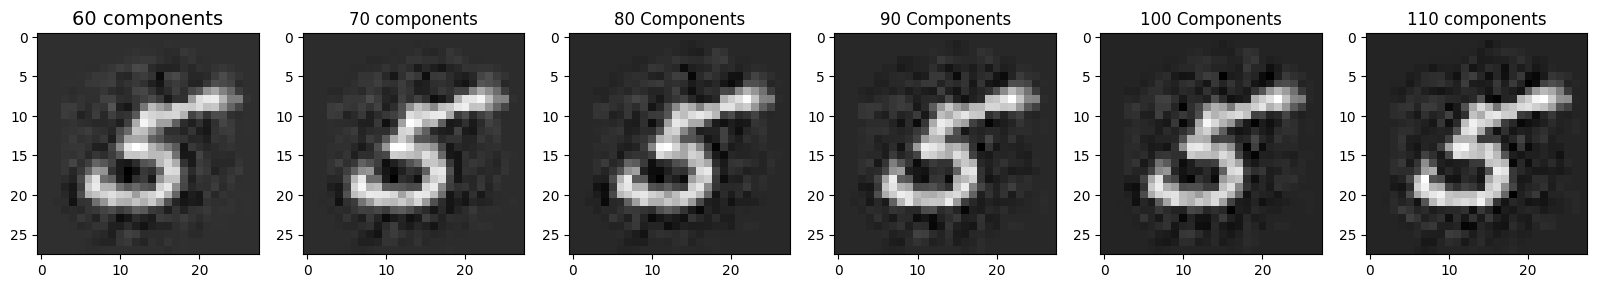

In [29]:
plt.clf()
plt.figure(figsize=(20,4));
#This means it is plotting the reconstructed image using 60 principal components,
# not the original 784-dimensional image.
# Original Image (784 components)
plt.subplot(1, 6, 1);
plt.imshow(pca_com(60, X_std)[260].reshape(28, 28),
              cmap = plt.cm.gray, interpolation='nearest');

plt.title('60 components', fontsize = 14);


# 10 principal components
plt.subplot(1, 6, 2);
plt.imshow(pca_com(70, X_std)[260].reshape(28, 28),
              cmap = plt.cm.gray, interpolation='nearest');
plt.title('70 components', fontsize = 12);



# 20 principal components
plt.subplot(1, 6, 3);
plt.imshow(pca_com(80, X_std)[260].reshape(28, 28),
              cmap = plt.cm.gray, interpolation='nearest');
plt.title('80 Components', fontsize = 12)


# 30 principal components
plt.subplot(1, 6, 4);
plt.imshow(pca_com(90, X_std)[260].reshape(28, 28),
              cmap = plt.cm.gray, interpolation='nearest');
plt.title('90 Components', fontsize = 12)


# 40 principal components
plt.subplot(1, 6, 5)
plt.imshow(pca_com(100, X_std)[260].reshape(28, 28),
              cmap = plt.cm.gray, interpolation='nearest');
plt.title('100 Components', fontsize = 12)

# 50 principal components
plt.subplot(1, 6, 6);
plt.imshow(pca_com(110, X_std)[260].reshape(28, 28),
              cmap = plt.cm.gray, interpolation='nearest');
plt.title('110 components', fontsize = 12);
plt.show()



#TASK 1 Bayesian Theorem
#Write your own Classifier

In [30]:
X = data.values
from sklearn.model_selection import train_test_split
X = data.iloc[:, :-1].values.astype(float)
y = data.iloc[:, -1].values.astype(int)
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=20, stratify=y)

In [31]:
from sklearn.naive_bayes import GaussianNB

classifier=GaussianNB()
classifier=classifier.fit(x_train,y_train)
Y_pred=classifier.predict(x_test)

In [32]:
print('The score for training data is', classifier.score(x_train,y_train))
print('The score for test data is',classifier.score(x_test,y_test))

The score for training data is 0.915
The score for test data is 0.74


# TASK 2
##Use the projected image of your Choice (reduce to 100-200 components of your choice + your classifier---> from ealier)


In [33]:
pca = PCA(.95) #choose your percentage
X_train_pca=pca.fit_transform(x_train)
X_test_pca=pca.transform(x_test)


In [34]:
np.shape(x_test)

(100, 784)

In [35]:
np.shape(X_test_pca)

(100, 106)

In [36]:
model_pca = GaussianNB().fit(X_train_pca, y_train)
#Trains a model with the reduced data
#Calculates the proportion of hits
print("Train accuracy:", model_pca.score(X_train_pca, y_train))
print("Test accuracy :", model_pca.score(X_test_pca, y_test))

Train accuracy: 0.9625
Test accuracy : 0.83


# TASK 3
##Use your 2D projection  with your 2 classifiers ( Original Image and projected image) to show the Discrimination regions
#Choose only 2 digits


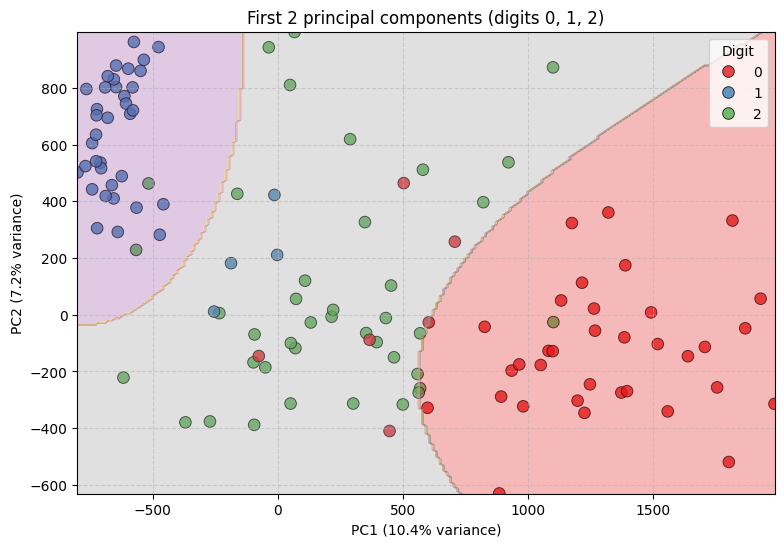

Variance explained by PC1 + PC2: 0.17648284183793558


In [37]:
import seaborn as sns

#Conserves the two highest variance directions
pca_2d = PCA(n_components=2)
X_train_pca2d = pca_2d.fit_transform(x_train)   # learn only with train

# Choose 3 digits that is wanted to draw
selected_digits = [0, 1, 2]
mask = np.isin(y_train, selected_digits)
#To see which images are from the selected_digits

X_plot = X_train_pca2d[mask] # Images from selected digits from x_train
y_plot = y_train[mask] #Images from selected digits from y_train

plt.figure(figsize=(9, 6))
#Draw graphic
sns.scatterplot( x=X_plot[:, 0], y=X_plot[:, 1], hue=y_plot,
    palette="Set1", s=70, alpha=0.8, edgecolor="k")

#Create the regions in the graphic
x_min, x_max = X_plot[:, 0].min() - 1, X_plot[:, 0].max() + 1
y_min, y_max = X_plot[:, 1].min() - 1, X_plot[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

g = GaussianNB()
g.fit(X_plot, y_plot)
Z = g.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

#Parameters to adjust
var = pca_2d.explained_variance_ratio_
plt.contourf(xx, yy, Z, alpha=0.3, cmap="Set1")      # decision zones
plt.xlabel(f"PC1 ({var[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({var[1]*100:.1f}% variance)")
plt.title("First 2 principal components (digits 0, 1, 2)")
plt.legend(title="Digit", loc="best")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

print("Variance explained by PC1 + PC2:", var.sum())

#Challenge use 10 digits

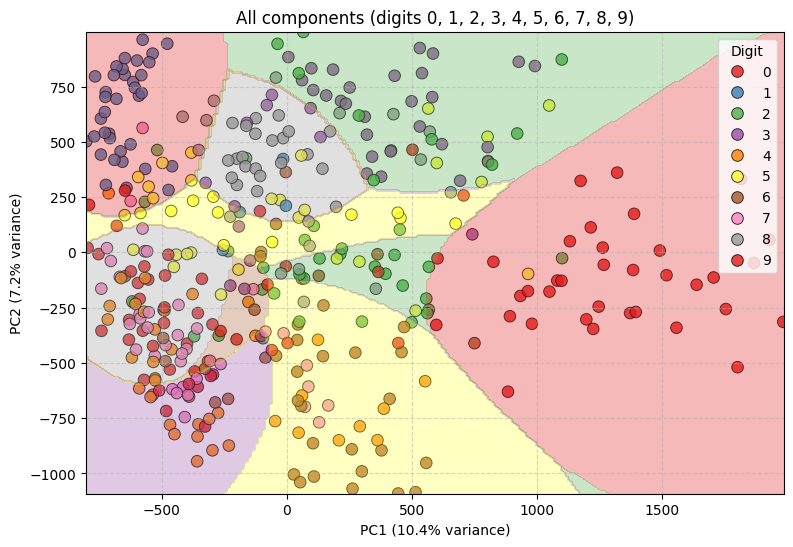

Variance explained by PC1 + PC2: 0.17648284183793558


In [38]:
selected_digits = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
mask = np.isin(y_train, selected_digits)
#To see which images are from the selected_digits

X_plot = X_train_pca2d[mask] # Images from selected digits from x_train
y_plot = y_train[mask] #Images from selected digits from y_train

plt.figure(figsize=(9, 6))
#Draw graphic
sns.scatterplot( x=X_plot[:, 0], y=X_plot[:, 1], hue=y_plot,
    palette="Set1", s=70, alpha=0.8, edgecolor="k")

#Create the regions in the graphic
x_min, x_max = X_plot[:, 0].min() - 1, X_plot[:, 0].max() + 1
y_min, y_max = X_plot[:, 1].min() - 1, X_plot[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

g = GaussianNB()
g.fit(X_plot, y_plot)
Z = g.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

#Parameters to adjust
var = pca_2d.explained_variance_ratio_
plt.contourf(xx, yy, Z, alpha=0.3, cmap="Set1")      # decision zones
plt.xlabel(f"PC1 ({var[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({var[1]*100:.1f}% variance)")
plt.title("All components (digits 0, 1, 2, 3, 4, 5, 6, 7, 8, 9)")
plt.legend(title="Digit", loc="best")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

print("Variance explained by PC1 + PC2:", var.sum())

Plot discrimination region

Accuracy 2D (train): 0.875


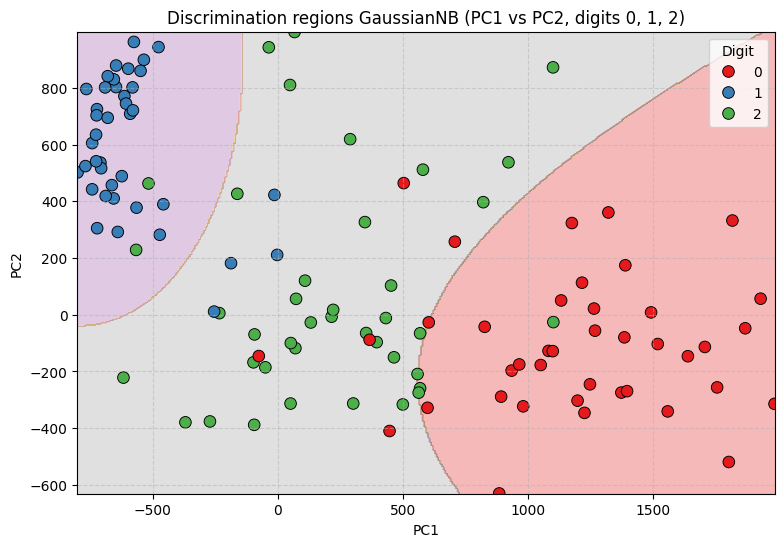

In [39]:

import numpy as np
import matplotlib.pyplot as plt

selected_digits = [0, 1, 2]
mask = np.isin(y_train, selected_digits)
#To see which images are from the selected_digits

X_plot = X_train_pca2d[mask] # Images from selected digits from x_train
y_plot = y_train[mask] #Images from selected digits from y_train

model_2d = GaussianNB().fit(X_plot, y_plot)
print("Accuracy 2D (train):", model_2d.score(X_plot, y_plot))

x_min, x_max = X_plot[:, 0].min() - 1, X_plot[:, 0].max() + 1
y_min, y_max = X_plot[:, 1].min() - 1, X_plot[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400),
                     np.linspace(y_min, y_max, 400))

Z = model_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)


plt.figure(figsize=(9, 6))
plt.grid(True, linestyle="--", alpha=0.5)
plt.contourf(xx, yy, Z, alpha=0.3, cmap="Set1")      # decision zones
sns.scatterplot(x=X_plot[:, 0], y=X_plot[:, 1], hue=y_plot,
                palette="Set1", s=70, edgecolor="k")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("Discrimination regions GaussianNB (PC1 vs PC2, digits 0, 1, 2)")
plt.legend(title="Digit")
plt.show()



TASK 4
Print

Comparation between PCA and only Gaussian

In [40]:
import time

t0 = time.time()
m_full = GaussianNB().fit(x_train, y_train)
t_full = time.time() - t0

t1 = time.time()
m_95= GaussianNB().fit(X_train_pca, y_train)
t_95 = time.time() - t1

d_full = x_train.shape[1]
d_95   = pca.n_components_

print(f"Times: \n full: { t_full:.5f} \n PCA:  {t_95:.5f}")

print("Complete dimension :", d_full)
print("Dimensions with PCA   :", d_95)
print(f"Reduction             : {(1 - d_95/d_full)*100:.1f}%")

m_full = GaussianNB().fit(x_train, y_train)
print("Test accuracy complete:", m_full.score(x_test, y_test))
print("Test accuracy PCA 95% :", model_pca.score(X_test_pca, y_test))


Times: 
 full: 0.00853 
 PCA:  0.00328
Complete dimension : 784
Dimensions with PCA   : 106
Reduction             : 86.5%
Test accuracy complete: 0.74
Test accuracy PCA 95% : 0.83


With PCA (95 % of the variance) the data goes from 784 to 185 dimensions (76.4 % reduction) and the test accuracy stays the same (0.76 vs 0.76), while the training time drops (0.0038 s vs 0.0087 s). The 0.95 refers to the variance kept by PCA. The first two components explain only 11.3 % of the variance, so in the 2D plots the classes overlap: the plot is only for visualization, not for classification.

Week 5

In [41]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

#Divide again, so that the data is the original
X = (data.iloc[:, :-1] > 128).astype(int).values
y = data.iloc[:, -1].values
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [42]:
print(x_train.shape, x_test.shape) #data is already divided, check dimmensions
model_lr = LogisticRegression(max_iter=1000).fit(x_train, y_train) #Train the LogisticRegression
print("LogReg  train:", model_lr.score(x_train, y_train)) #Verify accuracy
print("LogReg  test :", model_lr.score(x_test,  y_test)) #verify test accuracy

(400, 784) (100, 784)
LogReg  train: 1.0
LogReg  test : 0.87


Without StandardScaler

In [43]:
svm_rbf = SVC(kernel='rbf').fit(x_train, y_train) #Train support vector machine with rbf
 #(when data cannot be separated correctly with a lineal border)
svm_lin = SVC(kernel='linear').fit(x_train, y_train)#Train support vector machine with linear (lineal separation)

results = {
    "LogisticRegression": model_lr,
    "SVM linear": svm_lin,
    "SVM RBF": svm_rbf,
} #Aligns all the results in a dicctionary

table = pd.DataFrame({ #Dictionary/table of the elements in the results dictionary
    name: {"train": m.score(x_train, y_train), "test": m.score(x_test, y_test)}
    for name, m in results.items()
}).T
table["difference (train-test)"] = table["train"] - table["test"]
table

,train,test,difference (train-test)
LogisticRegression,1.00,0.87,0.13
SVM linear,1.00,0.88,0.12
SVM RBF,0.99,0.90,0.09


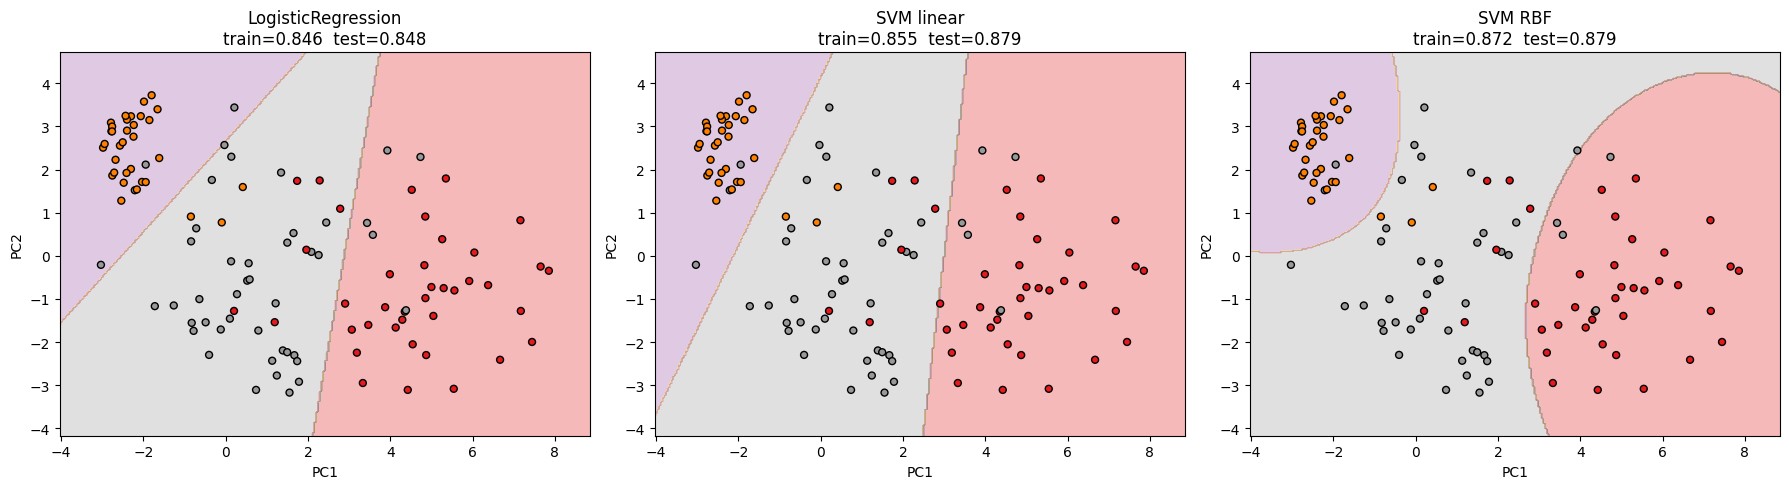

In [44]:
digits = [0, 1, 2]
pca2 = PCA(n_components=2).fit(x_train)          # PCA learned only with train
m_tr = np.isin(y_train, digits) #Elements in the digits array
m_te = np.isin(y_test,  digits)
Xtr2, ytr2 = pca2.transform(x_train[m_tr]), y_train[m_tr]
Xte2, yte2 = pca2.transform(x_test[m_te]),  y_test[m_te] #transform deleting the elements not on m_tr, m_te

models_2d = {
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "SVM linear": SVC(kernel='linear'),
    "SVM RBF": SVC(kernel='rbf'),
} #Dictionary with models

xx, yy = np.meshgrid(
    np.linspace(Xtr2[:, 0].min()-1, Xtr2[:, 0].max()+1, 300),
    np.linspace(Xtr2[:, 1].min()-1, Xtr2[:, 1].max()+1, 300)) #Paint the regions

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (nombre, m) in zip(axes, models_2d.items()):
    m.fit(Xtr2, ytr2)
    Z = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="Set1")
    ax.scatter(Xtr2[:, 0], Xtr2[:, 1], c=ytr2, cmap="Set1", edgecolor="k", s=25)
    ax.set_title(f"{nombre}\ntrain={m.score(Xtr2, ytr2):.3f}  test={m.score(Xte2, yte2):.3f}")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout();
plt.show()

With standardScaler

In [45]:
scaler = StandardScaler().fit(x_train)      # mean and deviation only with train
x_train_sc = scaler.transform(x_train)
x_test_sc  = scaler.transform(x_test)       # aply transformation to both

models_sc = { #dictionary with models
    "LogisticRegression + scaler": LogisticRegression(max_iter=1000),
    "SVM linear + scaler":         SVC(kernel='linear'),
    "SVM RBF + scaler":            SVC(kernel='rbf'),
}
for m in models_sc.values(): #Give to each model the train and test data
    m.fit(x_train_sc, y_train)

table_sc = pd.DataFrame({
    n: {"train": m.score(x_train_sc, y_train), "test": m.score(x_test_sc, y_test)}
    for n, m in models_sc.items() #Table of results and scores
}).T
table_sc["difference (train-test)"] = table_sc["train"] - table_sc["test"]
display(pd.concat([table, table_sc])) #Concatenate both tables, and display them to see the difference

,train,test,difference (train-test)
LogisticRegression,1.0000,0.87,0.1300
SVM linear,1.0000,0.88,0.1200
SVM RBF,0.9900,0.90,0.0900
LogisticRegression + scaler,1.0000,0.88,0.1200
SVM linear + scaler,1.0000,0.89,0.1100
SVM RBF + scaler,0.9925,0.80,0.1925


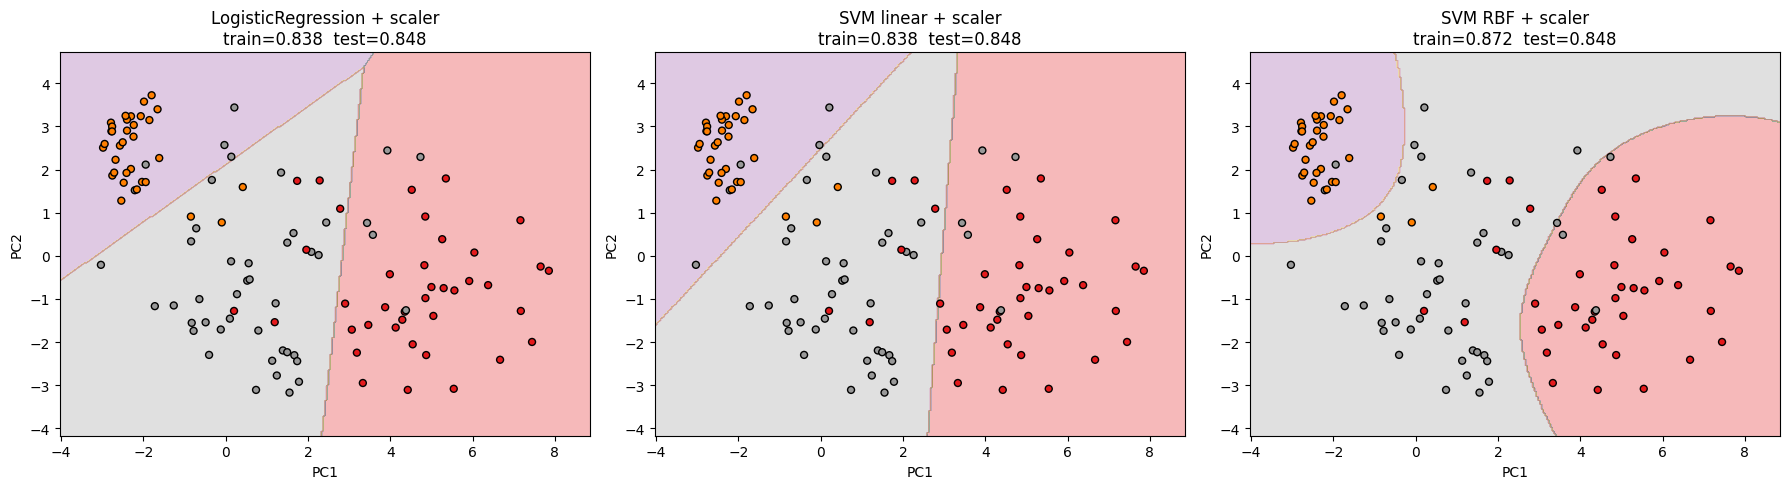

In [46]:
sc2 = StandardScaler().fit(Xtr2)                          # mean and deviation with train
Xtr2_sc = sc2.transform(Xtr2)
Xte2_sc = sc2.transform(Xte2)
grid_sc = sc2.transform(np.c_[xx.ravel(), yy.ravel()])    # sections escalated also (to adapt)

models_2d_sc = {
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "SVM linear":         SVC(kernel='linear'),
    "SVM RBF":            SVC(kernel='rbf'),
}
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (nombre, m) in zip(axes, models_2d_sc.items()):
    m.fit(Xtr2_sc, ytr2)
    Z = m.predict(grid_sc).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="Set1")
    ax.scatter(Xtr2[:, 0], Xtr2[:, 1], c=ytr2, cmap="Set1", edgecolor="k", s=25)  # original axis
    ax.set_title(f"{nombre} + scaler\ntrain={m.score(Xtr2_sc, ytr2):.3f}  test={m.score(Xte2_sc, yte2):.3f}")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout(); plt.show()

In [47]:
from sklearn.model_selection import StratifiedKFold
cv = StratifiedKFold(5, shuffle=True, random_state=42)

models_cv = {
    "LogReg":          (LogisticRegression(max_iter=1000), False),
    "SVM linear":      (SVC(kernel='linear'),              False),
    "SVM RBF":         (SVC(kernel='rbf'),                 False),
    "LogReg + scaler": (LogisticRegression(max_iter=1000), True),
    "SVM linear + sc": (SVC(kernel='linear'),              True),
    "SVM RBF + sc":    (SVC(kernel='rbf'),                 True),
}

res = {n: [] for n in models_cv}
for tr, va in cv.split(X, y):
    for n, (m, usar_sc) in models_cv.items():
        a, b = X[tr], X[va]
        if usar_sc:
            s = StandardScaler().fit(a)
            a, b = s.transform(a), s.transform(b)
        m.fit(a, y[tr])
        res[n].append(m.score(b, y[va]))

cv_tab = pd.DataFrame(res)
cv_tab.loc["mean"] = cv_tab.mean()
cv_tab.loc["std"]  = cv_tab.iloc[:5].std()
cv_tab.round(3)

,LogReg,SVM linear,SVM RBF,LogReg + scaler,SVM linear + sc,SVM RBF + sc
0,0.910,0.910,0.920,0.870,0.900,0.890
1,0.860,0.870,0.880,0.880,0.910,0.870
2,0.800,0.820,0.840,0.770,0.810,0.750
3,0.830,0.820,0.820,0.810,0.820,0.760
4,0.840,0.850,0.880,0.850,0.870,0.850
mean,0.848,0.854,0.868,0.836,0.862,0.824
std,0.041,0.038,0.039,0.046,0.045,0.065


## Observations

**Shape of the decision boundary**
- Logistic Regression and SVM linear give straight-line boundaries.
- SVM RBF gives curved, closed regions that bend around the data.

**Function used**
- LogReg: linear score w·x+b with softmax, trained with log-loss.
- SVM linear: same linear score, trained with hinge loss / maximum margin; only support vectors matter.
- SVM RBF: sum of kernel terms exp(-gamma*||xi-x||²) around the support vectors; non-linear, no coef_.

**Train / test score**
- All models reach ~1.00 on train but 0.87-0.90 on test (overfitting: 400 samples, 784 features).
- RBF has the best test score (0.90) and the smallest gap.
- The test set has only 100 images, so differences of 1-3 % are within the noise; the CV std is about 0.04.

**StandardScaler**
- Almost no effect on LogReg and SVM linear (pixels are already 0/1).
- It lowers SVM RBF (test 0.90 -> 0.80). Possible reason: rarely-active pixels get inflated and distort the kernel distances (not verified).
- The boundary shapes in 2D do not change.

Extra text with contents form week4

In [48]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.naive_bayes import GaussianNB

X = data.iloc[:, :-1].values.astype(float)
y = data.iloc[:, -1].values.astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Simulate a faulty sensor: randomly delete 5% of the pixel values
rng = np.random.default_rng(0)
def add_nan(A, frac=0.05):
    A = A.copy(); A[rng.random(A.shape) < frac] = np.nan; return A
Xtr_nan, Xte_nan = add_nan(X_train), add_nan(X_test)

# Deletion would drop almost every row, so we impute instead.
# Fit the imputer on TRAIN only and reuse it on test (same rule as scalers: no leakage).
# 1. Define your imputers in a dictionary
imputers = {
    "mean": SimpleImputer(strategy="mean"),
    "KNN": KNNImputer(n_neighbors=5)
}

# 2. Loop through each imputer cleanly
for name, imp in imputers.items():
    # Fill missing values for training and test data
    X_train_filled = imp.fit_transform(Xtr_nan)
    X_test_filled = imp.transform(Xte_nan)

    # Train the Gaussian Naive Bayes model
    model = GaussianNB()
    model.fit(X_train_filled, y_train)

    # Evaluate and print the accuracy
    acc = model.score(X_test_filled, y_test)
    print(f"{name} imputation -> accuracy {acc:.3f}")

# Optional: add_indicator=True appends a 0/1 "was this missing?" column per feature,
# useful when the fact of being missing is itself informative.
SimpleImputer(strategy="median", add_indicator=True)

mean imputation -> accuracy 0.340
KNN imputation -> accuracy 0.680


SimpleImputer(add_indicator=True, strategy='median')

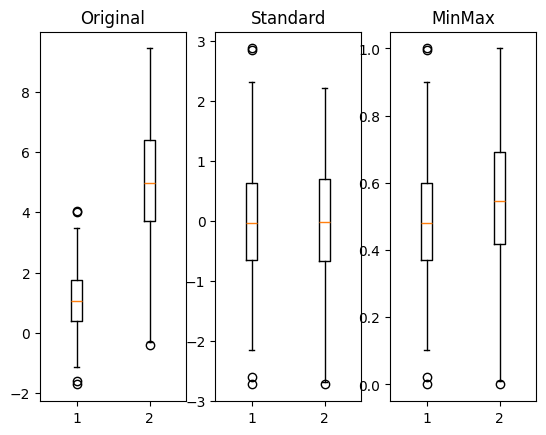

[1. 1. 1.]


In [49]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler, Normalizer

# Two features on different scales (like age vs income)
demo = np.c_[np.random.normal(1, 1, 200), np.random.normal(5, 2, 200)]

# StandardScaler: mean 0, variance 1 (per column)
demo_std = StandardScaler().fit_transform(demo)

# MinMaxScaler: values between 0 and 1 (per column)
demo_mm = MinMaxScaler().fit_transform(demo)

# Compare with boxplots
plt.subplot(1, 3, 1); plt.boxplot(demo);     plt.title("Original")
plt.subplot(1, 3, 2); plt.boxplot(demo_std); plt.title("Standard")
plt.subplot(1, 3, 3); plt.boxplot(demo_mm);  plt.title("MinMax")
plt.show()

# Normalizer: makes each ROW have length 1 (no fit needed)
features = np.array([[0.5, 0.5], [1.1, 3.4], [1.5, 20.2]])
new_feature = Normalizer().transform(features)
print(np.sum(new_feature**2, axis=1)**0.5)   # [1. 1. 1.]

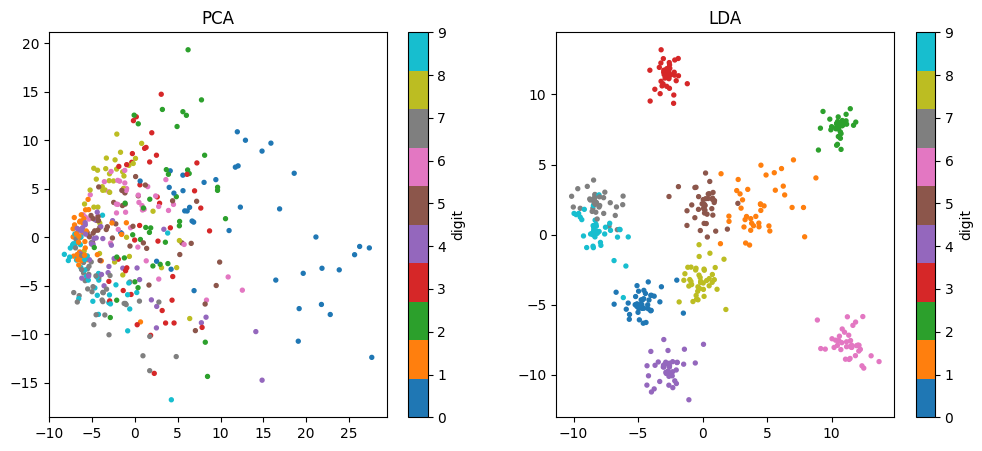

PCA accuracy: 0.37
LDA accuracy: 0.3


In [50]:
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

sc = StandardScaler().fit(X_train)
A, B = sc.transform(X_train), sc.transform(X_test)

# PCA ignores the labels (keeps max variance).
# LDA uses the labels (max between-class separation, min within-class spread),
# and gives at most (n_classes - 1) components, so 9 for digits.
pca2 = PCA(n_components=2).fit(A)
lda2 = LDA(n_components=2).fit(A, y_train)
# Step 1: project the data to 2D with each method
Z_pca = pca2.transform(A)   # PCA's 2 new features for every image
Z_lda = lda2.transform(A)   # LDA's 2 new features for every image

# Step 2: plot both, colored by digit
plt.figure(figsize=(12, 5))
#Creates an empty canvas 12 inches wide and 5 inches tall,
# big enough for two plots next to each other.

plt.subplot(1, 2, 1)
#Splits the canvas into 1 row and 2 columns, then selects the first
#(left) slot. Everything drawn next goes there. plt.subplot(1, 2, 2)
#later selects the right slot.
plt.scatter(Z_pca[:, 0], Z_pca[:, 1], c=y_train, cmap="tab10", s=8)

#Draws one dot per image:
#   Z_pca[:, 0] is each image’s first PCA feature and becomes the x position.
#   Z_pca[:, 1] is the second PCA feature and becomes the y position.
#   =y_train colors each dot by its true digit (0 to 9).
#   cmap="tab10" is the color palette, with 10 distinct colors for 10 digits.
#   s=8 is the dot size.

plt.title("PCA"); plt.colorbar(label="digit")

plt.subplot(1, 2, 2)
plt.scatter(Z_lda[:, 0], Z_lda[:, 1], c=y_train, cmap="tab10", s=8)
plt.title("LDA"); plt.colorbar(label="digit")

plt.show()

# Step 3: train a classifier on each 2D space and test it
nb_pca = GaussianNB().fit(Z_pca, y_train)
print("PCA accuracy:", nb_pca.score(pca2.transform(B), y_test))

nb_lda = GaussianNB().fit(Z_lda, y_train)
print("LDA accuracy:", nb_lda.score(lda2.transform(B), y_test))

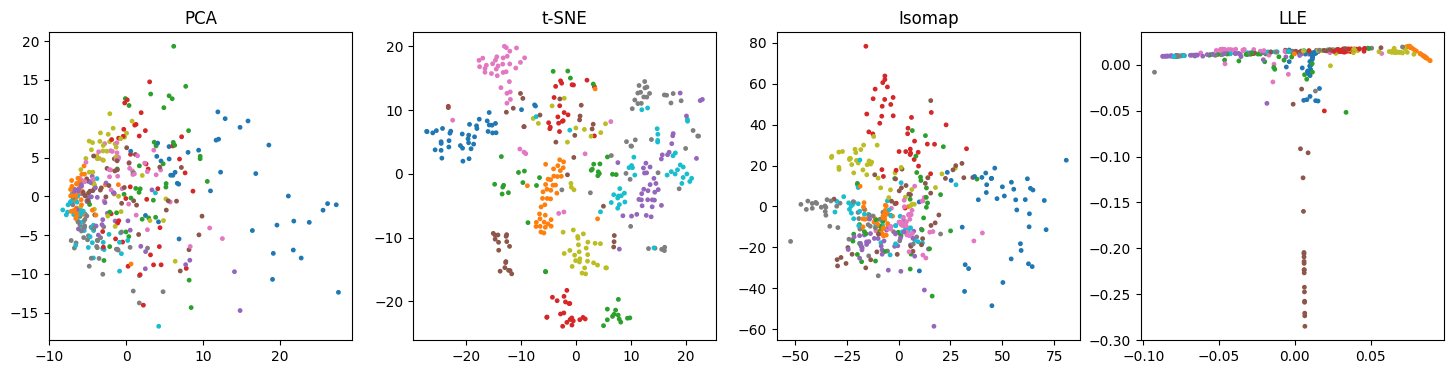

In [51]:
from sklearn.manifold import TSNE, Isomap, LocallyLinearEmbedding

# Step 1: take 1500 random images (these methods are slow on all of them)
n = min(1500, len(A))                      # never ask for more than we have
idx = np.random.choice(len(A), n, replace=False)
labels = y_train[idx]

# Step 2: shrink from 784 to 50 dims with PCA first (makes it faster)
S = PCA(n_components=50).fit_transform(A[idx])

# Step 3: reduce to 2D with each method
Z_pca = PCA(n_components=2).fit_transform(S)
Z_tsne = TSNE(n_components=2).fit_transform(S)
Z_iso = Isomap(n_components=2).fit_transform(S)
Z_lle = LocallyLinearEmbedding(n_components=2).fit_transform(S)

# Step 4: plot all four
plt.figure(figsize=(18, 4))
for i, (Z, name) in enumerate([(Z_pca, "PCA"), (Z_tsne, "t-SNE"), (Z_iso, "Isomap"), (Z_lle, "LLE")]):
    plt.subplot(1, 4, i + 1)
    plt.scatter(Z[:, 0], Z[:, 1], c=labels, cmap="tab10", s=6)
    plt.title(name)
plt.show()

###Extra part covering the contents missing of the presentation


####Linear regression
Searches for the best line that adjusts to the data with Height = a·Age + b

Slope a: 0.5626072041166382
Bias b: 124.88164665523155
Estimate at age 60: 158.63807890222984


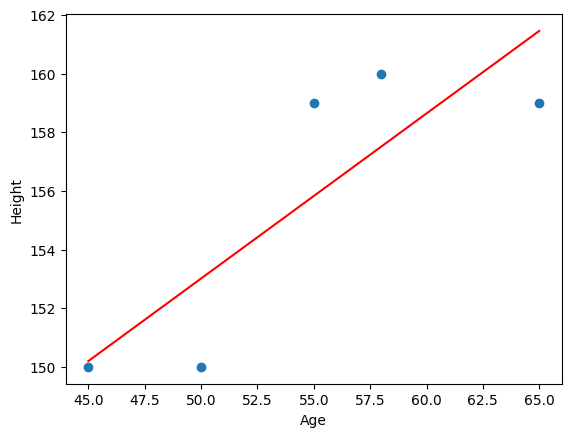

In [52]:
from sklearn.linear_model import LinearRegression

age = np.array([45, 50, 55, 58, 65])                      # input: age
height = np.array([150, 150, 159, 160, 159])              # output: height in cm

model = LinearRegression()                                # empty linear regression model
model.fit(age.reshape(-1, 1), height)                     # learn a and b (sklearn needs a column)

print("Slope a:", model.coef_[0])                         # cm gained per extra year
print("Bias b:", model.intercept_)                        # height predicted at age 0
print("Estimate at age 60:", model.predict([[60]])[0])    # predict a new person

plt.scatter(age, height)                                  # real data as points
plt.plot(age, model.predict(age.reshape(-1, 1)), color="red")   # fitted line
plt.xlabel("Age")                                         # x axis label
plt.ylabel("Height")                                      # y axis label
plt.show()                                                # show the figure

### Loss functions (SAE, SSE, RMSE)

In [53]:
pred1 = age + 99              # Model 1
pred2 = 0.5 * height + 130       # Model 2

for nombre, pred in [("Model 1", pred1), ("Model 2", pred2)]:
    error = pred - height
    sae = np.sum(np.abs(error))             # absolute error sum
    sse = np.sum(error ** 2)                # squared error add up
    rmse = np.sqrt(np.mean(error ** 2))     # # squared root of mean squared error
    print(nombre, "| SAE =", sae, "| SSE =", sse, "| RMSE =", round(rmse, 3))

Model 1 | SAE = 20 | SSE = 96 | RMSE = 4.382
Model 2 | SAE = 261.0 | SSE = 13650.5 | RMSE = 52.25


###Gradient descent
Method to find parameters that make the model error minimum



In [54]:
w = 0.0                                                   # starting value of w
step = 0.1                                                # learning rate: size of each step

for i in range(20):                                       # repeat 20 times
    loss = (w - 3) ** 2                                   # loss: smallest when w = 3
    derivative = 2 * (w - 3)                              # slope of the loss at the current w
    w = w - step * derivative                             # move against the slope (downhill)
    print("iter", i, "| w =", round(w, 4), "| loss =", round(loss, 4))   # w approaches 3

iter 0 | w = 0.6 | loss = 9.0
iter 1 | w = 1.08 | loss = 5.76
iter 2 | w = 1.464 | loss = 3.6864
iter 3 | w = 1.7712 | loss = 2.3593
iter 4 | w = 2.017 | loss = 1.5099
iter 5 | w = 2.2136 | loss = 0.9664
iter 6 | w = 2.3709 | loss = 0.6185
iter 7 | w = 2.4967 | loss = 0.3958
iter 8 | w = 2.5973 | loss = 0.2533
iter 9 | w = 2.6779 | loss = 0.1621
iter 10 | w = 2.7423 | loss = 0.1038
iter 11 | w = 2.7938 | loss = 0.0664
iter 12 | w = 2.8351 | loss = 0.0425
iter 13 | w = 2.8681 | loss = 0.0272
iter 14 | w = 2.8944 | loss = 0.0174
iter 15 | w = 2.9156 | loss = 0.0111
iter 16 | w = 2.9324 | loss = 0.0071
iter 17 | w = 2.946 | loss = 0.0046
iter 18 | w = 2.9568 | loss = 0.0029
iter 19 | w = 2.9654 | loss = 0.0019


With the gradient descend we calculate the best path that fits the dataset

Gradient descent doesn't calculate the line directly; instead, it looks for the values of the parameters (w and b) that minimize the error. Since those two numbers define the line, by finding them, you've found the best line.

In [57]:
import numpy as np
import pandas as pd

df2 = pd.read_csv("Weight_Height_M_W.csv")      # use the df2 you already loaded

x = df2["Weight"].values                         # input
y = df2["Height"].values                         # output

# Scale x (mean 0, std 1) so a single step size works well
x_s = (x - x.mean()) / x.std()

w, b = 0.0, 0.0                                  # starting slope and bias
step = 0.1                                       # learning rate

loss_hist = []                                   # loss at every iteration
w_hist = []                                      # w at every iteration
b_hist = []                                      # b at every iteration

for i in range(100):
    pred = w * x_s + b                           # current predictions
    error = pred - y                             # error of each person
    loss = np.mean(error ** 2)                   # mean squared error
    dw = 2 * np.mean(error * x_s)                # derivative of the loss with respect to w
    db = 2 * np.mean(error)                      # derivative of the loss with respect to b
    loss_hist.append(np.mean(error ** 2))        # save the loss BEFORE updating
    w_hist.append(w)                             # save the current w
    b_hist.append(b)                             # save the current b
    w = w - step * dw                            # move w against its slope
    b = b - step * db                            # move b against its slope
    if i % 20 == 0:
        print("iter", i, "| loss =", round(loss, 3), "| w =", round(w, 3), "| b =", round(b, 3))

# Convert back to the original units of Weight
slope = w / x.std()
intercept = b - slope * x.mean()
print("Height =", round(slope, 4), "* Weight +", round(intercept, 3))

iter 0 | loss = 26766.759 | w = 0.445 | b = 32.7
iter 20 | loss = 32.815 | w = 2.204 | b = 161.993
iter 40 | loss = 29.262 | w = 2.224 | b = 163.484
iter 60 | loss = 29.261 | w = 2.224 | b = 163.501
iter 80 | loss = 29.261 | w = 2.224 | b = 163.501
Height = 0.2847 * Weight + 147.12


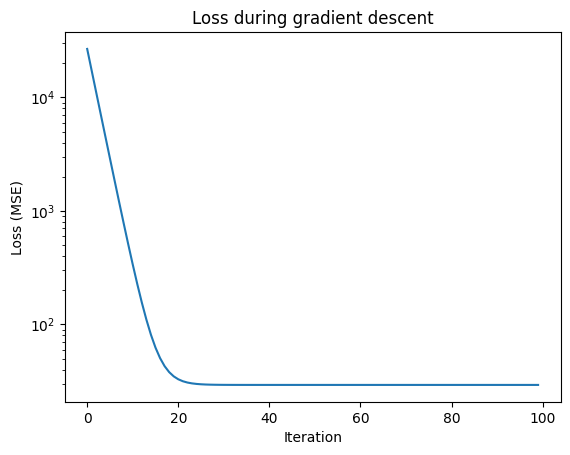

In [58]:
plt.plot(loss_hist)                              # loss at each iteration
plt.yscale("log")                                # log scale: the first loss is huge (26766)
plt.xlabel("Iteration")                          # x axis label
plt.ylabel("Loss (MSE)")                         # y axis label
plt.title("Loss during gradient descent")        # title
plt.show()                                       # show the figure

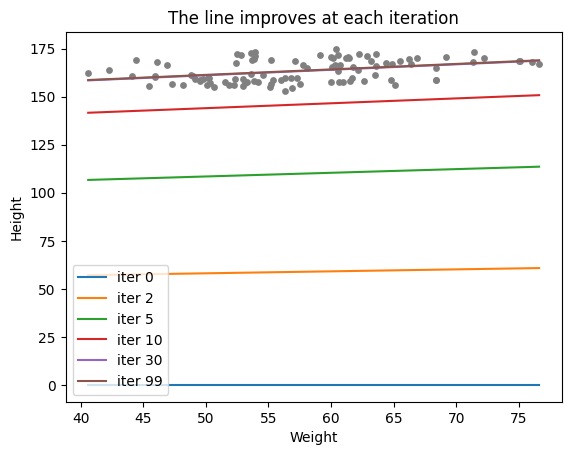

In [59]:
plt.scatter(x, y, s=15, color="gray")            # real data as grey points

xs = np.linspace(x.min(), x.max(), 100)          # weights from min to max
xs_s = (xs - x.mean()) / x.std()                 # scale them the same way as the training data

for k in [0, 2, 5, 10, 30, 99]:                  # iterations to draw
    plt.plot(xs, w_hist[k] * xs_s + b_hist[k], label="iter " + str(k))   # line at iteration k

plt.xlabel("Weight")                             # x axis label
plt.ylabel("Height")                             # y axis label
plt.legend()                                     # show which line is which
plt.title("The line improves at each iteration") # title
plt.show()                                       # show the figure

### Logistic Regression

The model learns two numbers, w and w0, and uses them in this formula:

y(x) = w·x + w0

- If y(x) is positive, the model predicts class 1 (woman).
- If y(x) is negative, the model predicts class 0 (man).
- The decision boundary is where y(x) = 0, the point where the model is 50/50.

What each number does:

- $w$ (weight): says which way the feature pushes the decision. Positive means a larger value favors class 1; negative means it favors class 0.
- $w_0$ (bias): moves the boundary to one side or the other.

Example: in this cell w = -0.56, so taller people are less likely to be women. The boundary is at -w0 / w = 159.9 cm.

####Calculation
1. Start with w = 0 and w0 = 0.

2. Calculate the probability given to each person with y = w·x + w0 and the sigmoid.

3. Measure the error with cross-entropy.

4. Calculate the derivative of the error with respect to w and w0.

5. Move w and w0 a bit so that the error goes down, and repeat.

In [66]:

height = np.array([150, 154, 160, 160, 165, 170]).reshape(-1, 1)
label = np.array([1, 1, 1, 0, 0, 0])

model = LogisticRegression()

#It can work with this too
#x = df2["Height"].values.reshape(-1, 1)

# Output: class of each person (1 = woman, 0 = man)
#y = (df2["gender"] == "W").astype(int).values


model.fit(height, label)

# w = slope of the discriminant y(x) = w*x + w0
w = model.coef_[0, 0]
# w0 = bias (intercept) of the discriminant
w0 = model.intercept_[0]

# Show both learned numbers
print("w =", w, "| w0 =", w0)

# The boundary is where w*x + w0 = 0, so x = -w0 / w (the model is 50/50 here)
print("Boundary height:", -w0 / w)

# predict_proba returns [P(man), P(woman)]; [0, 1] picks P(woman) for a person of 162 cm
print("Probability of being a woman at 162 cm:", model.predict_proba([[162]])[0, 1])
#162 · -0.5597863960726518 + 89.52577269978427 = -1.159562
#P(women) = 1 / (1 + e^(−y)) = 0.23874

w = -0.5597863960726518 | w0 = 89.52577269978427
Boundary height: 159.92845365282005
Probability of being a woman at 162 cm: 0.23873571044583966


###Binary cross entropy (Log Loss)
this evaluates how wrong a model is on its predictions


In [75]:
x = df2["Height"].values.reshape(-1, 1)
y = (df2["gender"] == "W").astype(int).values
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

model = LogisticRegression(max_iter=1000)
model.fit(x_train, y_train)

y_prob = model.predict_proba(x_test)[:, 1]

# Probability that the model gives to class 1 (woman) for each of the 6 examples
#p = np.array([0.5, 0.8, 0.9, 0.9, 0.2, 0.1])

# Real class of each example (1 = woman, 0 = man)
#t = np.array([1, 1, 1, 0, 0, 0])

# If t = 1 only -log(p) counts; if t = 0 only -log(1 - p) counts. The two terms are added
loss = -(y_test * np.log(y_prob) + (1 - y_test) * np.log(1 - y_prob))

# Error of each example (higher = model was more wrong and more confident)
print("Loss per example:", loss.round(4))
# Sum of all the errors
print("Total:", loss.sum().round(4))
# Average error (this is the value that gets minimized when training)
print("Mean:", loss.mean().round(4))

Loss per example: [0.   0.   1.45 0.   0.   0.   0.   0.   0.   0.02 0.42 0.   0.   0.
 0.   0.   0.   0.   0.   0.   0.  ]
Total: 1.8997
Mean: 0.0905


###Remember
predict is used for accuracy, confusion matrix, precision, and recall, which only need the class.

predict_proba is used for cross-entropy, log_loss, ROC curve, and AUC, which need the probability.

###Indexes vs one-hot encoding
Value to number

In [78]:
# A categorical column stored as text
seasons = pd.Series(["spring", "summer", "autumn", "winter", "summer"])
# Convert each category to a number (index encoding)
index_codes = seasons.map({"spring": 0, "summer": 1, "autumn": 2, "winter": 3})
# Problem: the model would think winter (3) is "bigger" than spring (0), which makes no sense
print(index_codes.values)
# One-hot: one column per category, with 1 where the row belongs to it and 0 elsewhere
one_hot = pd.get_dummies(seasons)
# astype(int) turns True/False into 1/0 so it is easier to read
print(one_hot.astype(int))

[0 1 2 3 1]
   autumn  spring  summer  winter
0       0       1       0       0
1       0       0       1       0
2       1       0       0       0
3       0       0       0       1
4       0       0       1       0


###Loss when the model has various classes

In [87]:
# Real class of each example in one-hot form
# (row 1 is class 0, row 2 is class 1, row 3 is class 2)
T = np.array([[1, 0, 0],[0, 1, 0], [0, 0, 1]])

# Probabilities predicted by the model (each row sums to 1)
P = np.array([[0.5, 0.3, 0.2],[0.2, 0.6, 0.2],[0.3, 0.4, 0.3]])

P = model.predict_proba(x_test)
# T: real class in one-hot form (man = [1, 0], woman = [0, 1])
T = np.eye(2)[y_test]

# T == 1 selects only the probability given to the correct class: [0.5, 0.6, 0.3]
correct_prob = P[T == 1]

# -log of that probability: small if the model was confident and right, large if not
loss = -np.log(correct_prob)

# Error of each example
print("Loss per example:", loss.round(4))
# Sum of the errors (should be 2.4079)
print("Total:", loss.sum().round(4))
# Average error (should be 0.8026)
print("Mean:", loss.mean().round(4))

Loss per example: [0.   0.   1.45 0.   0.   0.   0.   0.   0.   0.02 0.42 0.   0.   0.
 0.   0.   0.   0.   0.   0.   0.  ]
Total: 1.8997
Mean: 0.0905


###Confusion matrix by hand

In [88]:
# Rows = real class, columns = predicted class
M = np.array([[5, 2, 0],      # real Cat:    5 predicted Cat, 2 predicted Dog, 0 predicted Rabbit
              [3, 3, 2],      # real Dog:    3 predicted Cat, 3 predicted Dog, 2 predicted Rabbit
              [0, 1, 11]])    # real Rabbit: 0 predicted Cat, 1 predicted Dog, 11 predicted Rabbit

# Accuracy = correct predictions (the diagonal) divided by all predictions
accuracy = np.trace(M) / M.sum()

# Recall of Cat = cats found / all real cats (sum of the Cat ROW)
recall_cat = M[0, 0] / M[0, :].sum()

# Precision of Cat = cats found / everything predicted as Cat (sum of the Cat COLUMN)
precision_cat = M[0, 0] / M[:, 0].sum()

# Show the three metrics rounded to 3 decimals
print("Accuracy:", round(accuracy, 3))
print("Recall Cat:", round(recall_cat, 3))
print("Precision Cat:", round(precision_cat, 3))

Accuracy: 0.704
Recall Cat: 0.714
Precision Cat: 0.625
